# 00 · Ejecución y herramientas

[Índice del frontend](README.md) · [Siguiente · Arquitectura y reactividad](01_arquitectura_y_reactividad.ipynb)

El frontend es la aplicación que se ejecuta en el navegador. Su responsabilidad es representar las lecturas,
permitir seleccionar un dispositivo y consultar el historial con una sesión autenticada. El navegador carga HTML,
CSS y JavaScript. Node.js ejecuta las herramientas que transforman y sirven esos archivos durante el desarrollo.

## Requisitos del proyecto

Usa la pareja de versiones compatible con Vite y su plugin para Svelte. Los paquetes de este proyecto admiten
Node.js 20 desde 20.19, Node.js 22 desde 22.12 o Node.js 24 en adelante. npm viene con Node.js en la instalación
habitual. En la terminal, compara tu versión antes de instalar.

```bash
node --version
npm --version
```

Para iniciar sesión o consultar lecturas, la API debe estar disponible. Vite puede mostrar el formulario de acceso
con la API detenida, porque el formulario pertenece al paquete de recursos del frontend.

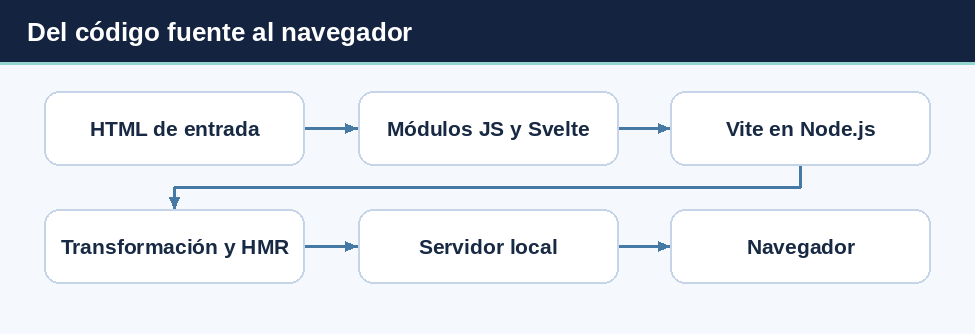

## Qué aporta cada tecnología

| Tecnología | Dónde corre | Papel en el proyecto |
| --- | --- | --- |
| HTML | Navegador | Declara la raíz `#app`, el idioma `es-MX` y el punto de entrada de JavaScript. |
| JavaScript moderno | Navegador y herramientas Node.js | Lee respuestas HTTP, adapta datos, configura gráficas y reacciona a eventos. |
| Svelte 5 | El compilador corre en Node.js y el código compilado corre en el navegador | Convierte componentes `.svelte` en código que actualiza la interfaz al cambiar el estado. |
| Vite | Node.js | Resuelve imports, integra el compilador, sirve archivos y reenvía solicitudes de API en dev y preview. |
| npm | Terminal | Instala dependencias y ejecuta los scripts declarados en `package.json`. |
| CSS | Navegador | Define cuadrículas, navegación adaptable, tamaño de la gráfica, foco y contraste. |
| Chart.js y Lucide | Navegador | Dibuja la serie en canvas y aporta iconos como componentes Svelte. |

`package.json` declara las dependencias y comandos. `package-lock.json` fija el árbol de versiones resuelto.
`npm ci` instala las versiones fijadas y prepara `node_modules` desde el archivo de bloqueo. Usa `npm install`
cuando quieras incorporar o actualizar una dependencia de forma deliberada y revisar el archivo de bloqueo
resultante. La carpeta de paquetes se regenera en cada instalación limpia.

- [package.json](../../frontend/package.json)
- [index.html](../../frontend/index.html)

## Arranque para desarrollo

Desde la raíz `ESP32`, ejecuta los comandos en una terminal dedicada al frontend.

```bash
cd frontend
npm ci
npm run dev -- --host 127.0.0.1 --port 5173 --strictPort
```

Abre `http://127.0.0.1:5173/`. Usa el mismo host durante toda la sesión del navegador. Con esos argumentos,
Vite se queda en el puerto indicado y avisa si ya está ocupado. Detén el proceso con Ctrl+C cuando termines.
En terminales posteriores puedes ejecutar directamente `npm run dev` si las dependencias ya están instaladas.
HMR actualiza módulos durante las ediciones y puede preservar su estado cuando el cambio lo permite.
Al recargar la página, `App.svelte` vuelve a consultar si hay una sesión vigente.

### Destino de la API

Vite reenvía `/api` a `http://127.0.0.1:8000` por defecto. Si la API usa otro puerto, coloca una línea como la
siguiente en `frontend/.env.local` y vuelve a iniciar Vite. El valor identifica un destino para el proxy.
Las credenciales de acceso se ingresan en la vista de inicio de sesión.

```dotenv
API_TARGET=http://127.0.0.1:8001
```

[vite.config.js](../../frontend/vite.config.js)

## Compilación y vista previa

Para generar los archivos de entrega desde `ESP32/frontend`, ejecuta `npm run build`.
El resultado queda en `frontend/dist`. `dist/index.html` referencia archivos empaquetados bajo `dist/assets`.
El archivo HTML compilado se abre mediante un servidor HTTP. Esa entrega también requiere una ruta `/api`
en el mismo origen que el sitio para iniciar sesión y consultar datos.

```bash
npm run build
npm run preview -- --host 127.0.0.1 --port 4173 --strictPort
```

Abre `http://127.0.0.1:4173/` para revisar la versión compilada. Vite conserva el proxy de `/api` durante
esta vista previa. Después de modificar el código, vuelve a compilar para ver el cambio en preview.
El proyecto también puede entregar la compilación desde el mismo servicio que publica la API en el puerto
8000. En esa modalidad se carga `http://127.0.0.1:8000/` y Vite deja de ser necesario para atender el
navegador.

| Modo | Fuente servida | Puerto de este ejemplo | Tras una edición |
| --- | --- | --- | --- |
| `dev` | Código transformado al solicitarlo | 5173 | Vite aplica HMR. |
| `preview` | Archivos de `dist` | 4173 | Ejecuta nuevamente `npm run build`. |
| Entrega de la aplicación | Archivos de `dist` | 8000 | Compila antes de comenzar a servir los archivos. |

## Comprobación rápida

Conserva Vite en ejecución y abre otra terminal. La primera comprobación verifica que carga HTML.
La segunda comprueba el acceso a una ruta protegida sin sesión.

```bash
curl -fsS http://127.0.0.1:5173/ -o /dev/null
curl -sS -o /dev/null -w '%{http_code}\n' http://127.0.0.1:5173/api/auth/me
```

Si la segunda devuelve `401`, el proxy llegó a la API y esta pidió autenticación. Observa ahora en el navegador
cómo cambia la interfaz al entrar con una cuenta del dashboard. Puedes seguir la petición y su respuesta desde
**Herramientas de desarrollador → Red**.

[Índice del frontend](README.md) · [Siguiente · Arquitectura y reactividad](01_arquitectura_y_reactividad.ipynb)